Device: cuda
Zip files already present, skipping download.
[SMD] dim=38  train=566724  val=141681  test=708420  anomaly rate in test=4.16%
[SMD] Phase 1
  [phase1] epoch   1  train loss 0.45383  val loss 0.19768
  [phase1] epoch   2  train loss 0.23471  val loss 0.12832
  [phase1] epoch   3  train loss 0.18667  val loss 0.09529
  [phase1] epoch   4  train loss 0.16287  val loss 0.07195
  [phase1] epoch   5  train loss 0.14823  val loss 0.05673
  [phase1] epoch   6  train loss 0.13823  val loss 0.04738
  [phase1] epoch   7  train loss 0.12985  val loss 0.04018
  [phase1] epoch   8  train loss 0.12315  val loss 0.03327
  [phase1] epoch   9  train loss 0.11933  val loss 0.03001
  [phase1] epoch  10  train loss 0.11303  val loss 0.02787
  [phase1] epoch  11  train loss 0.10859  val loss 0.02327
  [phase1] epoch  12  train loss 0.10455  val loss 0.02331
  [phase1] epoch  13  train loss 0.10088  val loss 0.01858
  [phase1] epoch  14  train loss 0.09983  val loss 0.01853
  [phase1] epoch  15 

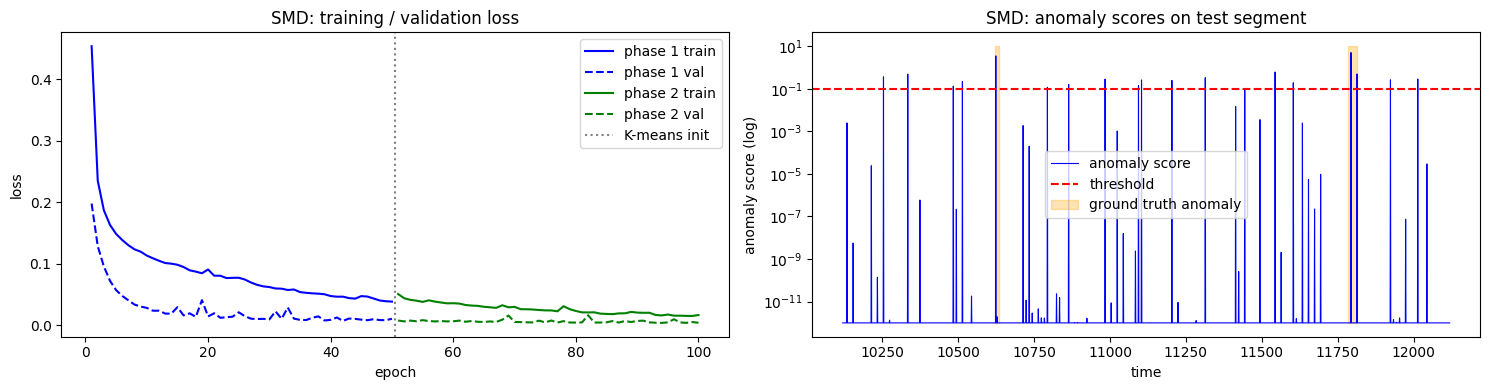

[SMD] threshold=0.0958961  Precision=88.00  Recall=98.26  F1=92.85

[MSL] dim=55  train=46653  val=11664  test=73729  anomaly rate in test=10.54%
[MSL] Phase 1
  [phase1] epoch   1  train loss 0.61778  val loss 0.53907
  [phase1] epoch   2  train loss 0.59202  val loss 0.51706
  [phase1] epoch   3  train loss 0.56805  val loss 0.49148
  [phase1] epoch   4  train loss 0.54032  val loss 0.46201
  [phase1] epoch   5  train loss 0.51023  val loss 0.43235
  [phase1] epoch   6  train loss 0.47814  val loss 0.39748
  [phase1] epoch   7  train loss 0.44832  val loss 0.36633
  [phase1] epoch   8  train loss 0.42178  val loss 0.33730
  [phase1] epoch   9  train loss 0.39944  val loss 0.31422
  [phase1] epoch  10  train loss 0.38243  val loss 0.29730
  [phase1] epoch  11  train loss 0.37278  val loss 0.28430
  [phase1] epoch  12  train loss 0.36202  val loss 0.27210
  [phase1] epoch  13  train loss 0.35013  val loss 0.25801
  [phase1] epoch  14  train loss 0.34336  val loss 0.25622
  [phase1] epo

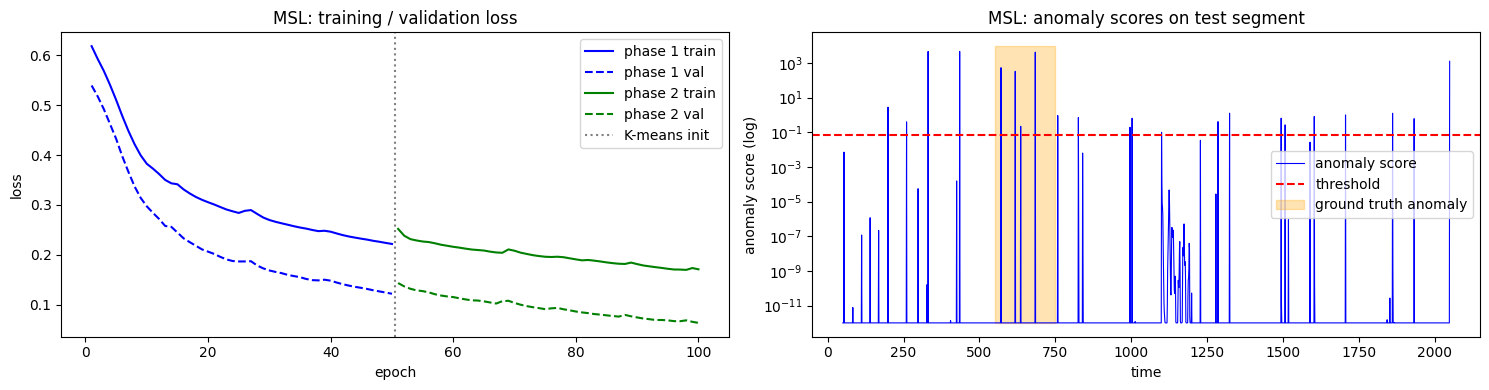

[MSL] threshold=0.0727813  Precision=91.72  Recall=93.84  F1=92.77

[SMAP] dim=25  train=108146  val=27037  test=427617  anomaly rate in test=12.79%
[SMAP] Phase 1
  [phase1] epoch   1  train loss 0.94723  val loss 0.31956
  [phase1] epoch   2  train loss 0.74607  val loss 0.24318
  [phase1] epoch   3  train loss 0.66497  val loss 0.21865
  [phase1] epoch   4  train loss 0.63491  val loss 0.20199
  [phase1] epoch   5  train loss 0.59331  val loss 0.17785
  [phase1] epoch   6  train loss 0.55665  val loss 0.16392
  [phase1] epoch   7  train loss 0.53104  val loss 0.14564
  [phase1] epoch   8  train loss 0.49887  val loss 0.13477
  [phase1] epoch   9  train loss 0.48475  val loss 0.12568
  [phase1] epoch  10  train loss 0.45352  val loss 0.10524
  [phase1] epoch  11  train loss 0.42203  val loss 0.09045
  [phase1] epoch  12  train loss 0.39898  val loss 0.07741
  [phase1] epoch  13  train loss 0.39414  val loss 0.09193
  [phase1] epoch  14  train loss 0.38873  val loss 0.06928
  [phase1]

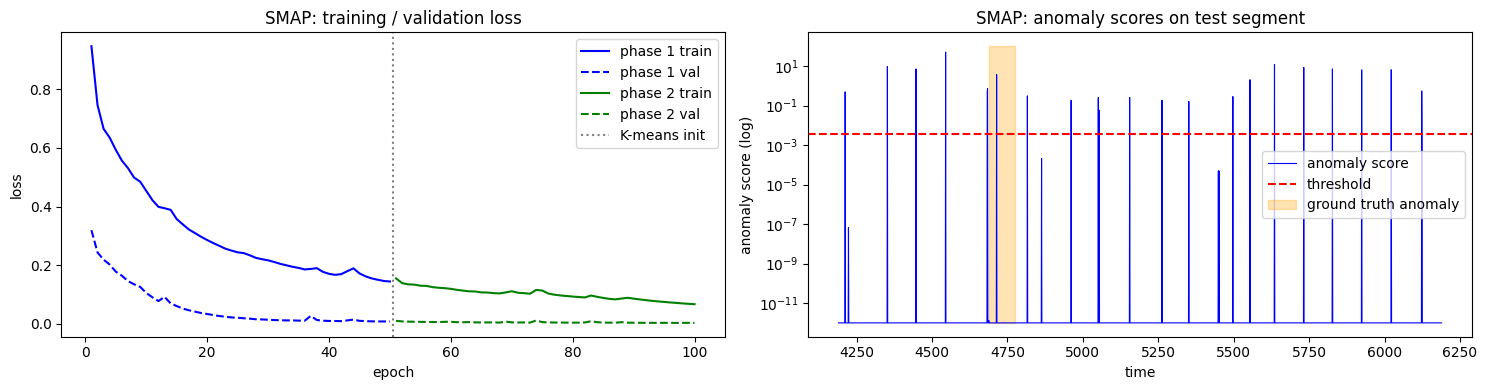

[SMAP] threshold=0.0036979  Precision=93.38  Recall=87.53  F1=90.36

[PSM] dim=25  train=105984  val=26497  test=87841  anomaly rate in test=27.73%
[PSM] Phase 1
  [phase1] epoch   1  train loss 0.46996  val loss 0.92495
  [phase1] epoch   2  train loss 0.24776  val loss 0.67985
  [phase1] epoch   3  train loss 0.17533  val loss 0.43529
  [phase1] epoch   4  train loss 0.13135  val loss 0.33480
  [phase1] epoch   5  train loss 0.11130  val loss 0.29641
  [phase1] epoch   6  train loss 0.09655  val loss 0.25010
  [phase1] epoch   7  train loss 0.08495  val loss 0.21838
  [phase1] epoch   8  train loss 0.07851  val loss 0.22471
  [phase1] epoch   9  train loss 0.06964  val loss 0.19219
  [phase1] epoch  10  train loss 0.06113  val loss 0.16648
  [phase1] epoch  11  train loss 0.05474  val loss 0.14992
  [phase1] epoch  12  train loss 0.04793  val loss 0.13519
  [phase1] epoch  13  train loss 0.04262  val loss 0.13208
  [phase1] epoch  14  train loss 0.03921  val loss 0.12925
  [phase1] e

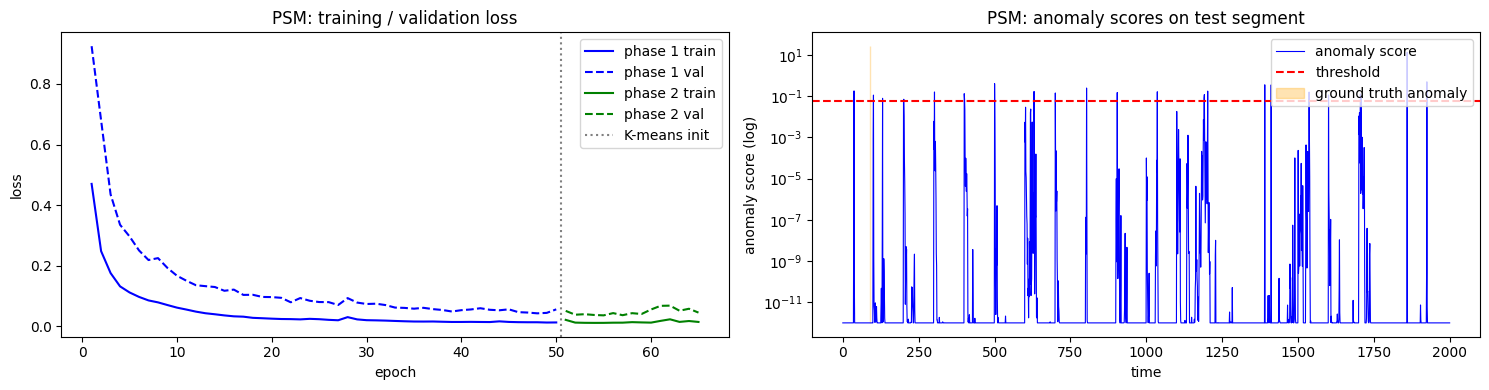

[PSM] threshold=0.0564076  Precision=96.24  Recall=99.27  F1=97.73

dataset     P     R    F1
    SMD 88.00 98.26 92.85
    MSL 91.72 93.84 92.77
   SMAP 93.38 87.53 90.36
    PSM 96.24 99.27 97.73
    avg 92.34 94.72 93.43


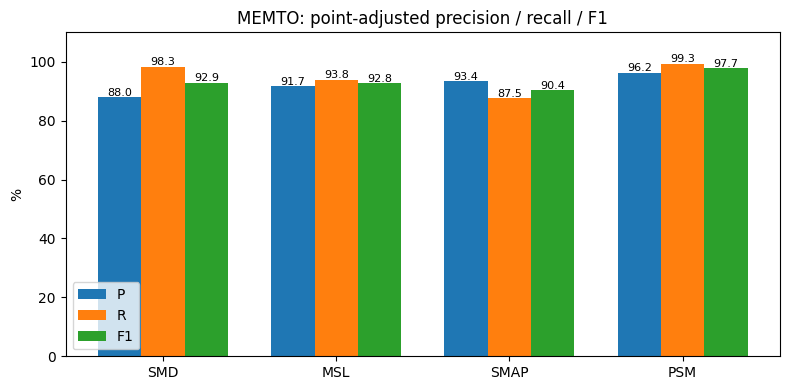

In [4]:
# =============================================================================
# MEMTO: Memory-guided Transformer for Multivariate Time Series Anomaly Detection
# Datasets: SMD, MSL, SMAP, PSM
# =============================================================================

import os, glob, math, copy, random, subprocess, sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import precision_recall_fscore_support

# ----------------------------------------------------------------------------
# 0. Configuration (values from the paper, Section 4.1 and Appendix A)
# ----------------------------------------------------------------------------
class Config:
    data_root   = "./dataset"
    # Public folder shared by the Anomaly Transformer authors (SMD, MSL, SMAP, PSM)
    gdrive_url  = "https://drive.google.com/drive/folders/1gisthCoE-RrKJ0j3KPV7xiibhHWT9qRm"
    datasets    = ["SMD", "MSL", "SMAP", "PSM"]
    anomaly_ratio = {"SMD": 0.5, "MSL": 1.0, "SMAP": 1.0, "PSM": 1.0}   # p(%) - Table 6

    win_size    = 100      # sub-series length L
    step        = 100      # non-overlapped sliding window
    val_ratio   = 0.2      # 80% train / 20% validation

    d_model     = 512      # latent dimension C
    n_heads     = 8
    e_layers    = 3
    d_ff        = 512
    dropout     = 0.0

    n_memory    = 10       # M (number of memory items = number of K-means clusters)
    tau         = 0.1      # softmax temperature
    lambd       = 0.01     # weight of the entropy loss
    lr          = 5e-5
    batch_size  = 32
    max_epochs  = 50       # upper bound per phase; early stopping usually ends sooner
    patience    = 10       # early stopping patience on validation loss
    kmeans_frac = 0.10     # fraction of training sub-series used for K-means

    reinit_phase2 = False  # True: re-initialise encoder/decoder weights before phase 2
    seed        = 2023
    device      = "cuda" if torch.cuda.is_available() else "cpu"

cfg = Config()


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


# ----------------------------------------------------------------------------
# 1. Data
# ----------------------------------------------------------------------------
def download_data():
    import zipfile
    zips = glob.glob(os.path.join(cfg.data_root, "**", "*.zip"), recursive=True)
    if not zips:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "gdown"], check=True)
        import gdown
        gdown.download_folder(url=cfg.gdrive_url, output=cfg.data_root, quiet=False)
        zips = glob.glob(os.path.join(cfg.data_root, "**", "*.zip"), recursive=True)
    else:
        print("Zip files already present, skipping download.")
    # The Drive folder holds one zip per dataset: extract each into dataset/<NAME>/
    for z in zips:
        name = os.path.splitext(os.path.basename(z))[0]
        target = os.path.join(cfg.data_root, name)
        if not os.path.isdir(target):
            print(f"Extracting {os.path.basename(z)} ...")
            with zipfile.ZipFile(z) as f:
                f.extractall(target)


def _find(pattern):
    hits = glob.glob(os.path.join(cfg.data_root, "**", pattern), recursive=True)
    if not hits:
        raise FileNotFoundError(
            f"Could not find '{pattern}' under {cfg.data_root}. "
            "Check that the download finished, or upload the files manually.")
    return hits[0]


def load_raw(name):
    """Returns train (T,n), test (T',n), test labels (T',)"""
    if name == "PSM":
        train = pd.read_csv(_find(os.path.join("PSM", "train.csv"))).values[:, 1:]
        test  = pd.read_csv(_find(os.path.join("PSM", "test.csv"))).values[:, 1:]
        label = pd.read_csv(_find(os.path.join("PSM", "test_label.csv"))).values[:, 1:]
        train = np.nan_to_num(train.astype(np.float64))
        test  = np.nan_to_num(test.astype(np.float64))
    else:
        train = np.load(_find(f"{name}_train.npy"))
        test  = np.load(_find(f"{name}_test.npy"))
        label = np.load(_find(f"{name}_test_label.npy"))
    label = np.asarray(label).reshape(-1).astype(int)

    scaler = StandardScaler().fit(train)
    train = scaler.transform(train).astype(np.float32)
    test  = scaler.transform(test).astype(np.float32)
    return train, test, label


class WindowDataset(Dataset):
    def __init__(self, data, win, step):
        self.data, self.win, self.step = data, win, step
        self.n = (len(data) - win) // step + 1

    def __len__(self):
        return self.n

    def __getitem__(self, i):
        s = i * self.step
        return torch.from_numpy(self.data[s:s + self.win])


def make_loaders(name):
    train, test, label = load_raw(name)
    split = int(len(train) * (1 - cfg.val_ratio))
    tr, va = train[:split], train[split:]

    tr_ds = WindowDataset(tr, cfg.win_size, cfg.step)
    va_ds = WindowDataset(va, cfg.win_size, cfg.step)
    te_ds = WindowDataset(test, cfg.win_size, cfg.win_size)   # test is always non-overlapped
    label = label[: len(te_ds) * cfg.win_size]                # drop the incomplete tail window

    kw = dict(batch_size=cfg.batch_size, num_workers=2, pin_memory=True)
    loaders = {
        "train":      DataLoader(tr_ds, shuffle=True,  **kw),
        "train_eval": DataLoader(tr_ds, shuffle=False, **kw),
        "val":        DataLoader(va_ds, shuffle=False, **kw),
        "test":       DataLoader(te_ds, shuffle=False, **kw),
    }
    print(f"[{name}] dim={train.shape[1]}  train={len(tr)}  val={len(va)}  test={len(test)}  "
          f"anomaly rate in test={label.mean()*100:.2f}%")
    return loaders, label, train.shape[1], tr_ds


# ----------------------------------------------------------------------------
# 2. Model
# ----------------------------------------------------------------------------
class PositionalEmbedding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).float().unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * -(math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return self.pe[:, : x.size(1)]


class DataEmbedding(nn.Module):
    def __init__(self, c_in, d_model, dropout):
        super().__init__()
        self.token = nn.Conv1d(c_in, d_model, kernel_size=3, padding=1,
                               padding_mode="circular", bias=False)
        self.pos = PositionalEmbedding(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):                      # x: (B, L, n)
        tok = self.token(x.permute(0, 2, 1)).transpose(1, 2)
        return self.drop(tok + self.pos(x))


class GatedMemoryModule(nn.Module):
    """Section 3.1.2: gated memory update stage + query update stage."""
    def __init__(self, n_memory, d_model, tau):
        super().__init__()
        self.tau = tau
        self.U = nn.Linear(d_model, d_model)   # U_psi
        self.W = nn.Linear(d_model, d_model)   # W_psi
        # Memory items are updated incrementally (Eq. 3), not by gradient descent.
        self.register_buffer("mem", F.normalize(torch.rand(n_memory, d_model), dim=1))

    @torch.no_grad()
    def set_memory(self, items):
        self.mem.copy_(items.to(self.mem.device, self.mem.dtype))

    def update(self, q):
        """Eq. (1)-(3).  q: (T, C) - all queries in the mini-batch."""
        logits = self.mem @ q.t() / self.tau              # (M, T)
        v = F.softmax(logits, dim=1)                      # softmax over queries, Eq. (1)
        agg = v @ q                                       # sum_t v_{i,t} q_t   -> (M, C)
        psi = torch.sigmoid(self.U(self.mem) + self.W(agg))          # Eq. (2)
        return (1 - psi) * self.mem + psi * agg                       # Eq. (3)

    def read(self, q, mem):
        """Eq. (4)-(5).  q: (B, L, C)"""
        logits = q @ mem.t() / self.tau                   # (B, L, M)
        w = F.softmax(logits, dim=-1)                     # Eq. (4)
        q_tilde = w @ mem                                 # Eq. (5)  -> (B, L, C)
        return q_tilde, w

    def forward(self, q, update_memory):
        mem = self.mem
        if update_memory:                                 # only during training
            mem = self.update(q.reshape(-1, q.size(-1)))
        q_tilde, w = self.read(q, mem)
        if update_memory:
            self.mem = mem.detach()
        q_hat = torch.cat([q, q_tilde], dim=-1)           # updated queries, (B, L, 2C)
        return q_hat, w


class MEMTO(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.embed = DataEmbedding(n_features, cfg.d_model, cfg.dropout)
        layer = nn.TransformerEncoderLayer(cfg.d_model, cfg.n_heads, cfg.d_ff, cfg.dropout,
                                           activation="gelu", batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, cfg.e_layers, norm=nn.LayerNorm(cfg.d_model))
        self.memory = GatedMemoryModule(cfg.n_memory, cfg.d_model, cfg.tau)
        # "Weak decoder": two fully-connected layers
        self.decoder = nn.Sequential(nn.Linear(2 * cfg.d_model, cfg.d_model),
                                     nn.ReLU(),
                                     nn.Linear(cfg.d_model, n_features))

    def encode(self, x):
        return self.encoder(self.embed(x))                # queries q: (B, L, C)

    def forward(self, x):
        q = self.encode(x)
        q_hat, w = self.memory(q, update_memory=self.training)
        x_hat = self.decoder(q_hat)
        return x_hat, q, w


# ----------------------------------------------------------------------------
# 3. Losses, training, K-means initialisation
# ----------------------------------------------------------------------------
def memto_loss(x, x_hat, w):
    rec = F.mse_loss(x_hat, x)                                        # Eq. (6)
    entr = (-w * torch.log(w + 1e-12)).sum(-1).mean()                 # Eq. (7)
    return rec + cfg.lambd * entr, rec, entr                          # Eq. (8)


@torch.no_grad()
def validate(model, loader):
    model.eval()
    total, n = 0.0, 0
    for x in loader:
        x = x.to(cfg.device)
        x_hat, _, w = model(x)
        loss, _, _ = memto_loss(x, x_hat, w)
        total += loss.item() * len(x); n += len(x)
    return total / max(n, 1)


def train_phase(model, loaders, tag):
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    best, best_state, bad = float("inf"), None, 0
    hist = {"train": [], "val": []}
    for epoch in range(1, cfg.max_epochs + 1):
        model.train()
        tot, n = 0.0, 0
        for x in loaders["train"]:
            x = x.to(cfg.device)
            x_hat, _, w = model(x)
            loss, _, _ = memto_loss(x, x_hat, w)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(x); n += len(x)
        val = validate(model, loaders["val"])
        print(f"  [{tag}] epoch {epoch:3d}  train loss {tot/n:.5f}  val loss {val:.5f}")
        hist["train"].append(tot / n); hist["val"].append(val)
        if val < best - 1e-6:
            best, bad = val, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= cfg.patience:
                print(f"  [{tag}] early stopping")
                break
    model.load_state_dict(best_state)
    return model, hist


@torch.no_grad()
def kmeans_memory_init(model, train_ds):
    """Algorithm 1: cluster the queries of 10% randomly sampled training sub-series."""
    model.eval()
    n = max(1, int(len(train_ds) * cfg.kmeans_frac))
    idx = np.random.choice(len(train_ds), n, replace=False)
    qs = []
    for i in range(0, n, cfg.batch_size):
        x = torch.stack([train_ds[j] for j in idx[i:i + cfg.batch_size]]).to(cfg.device)
        qs.append(model.encode(x).reshape(-1, cfg.d_model).cpu())
    qs = torch.cat(qs).numpy()
    km = KMeans(n_clusters=cfg.n_memory, n_init=10, random_state=cfg.seed).fit(qs)
    return torch.tensor(km.cluster_centers_, dtype=torch.float32)


# ----------------------------------------------------------------------------
# 4. Anomaly scoring and evaluation
# ----------------------------------------------------------------------------
@torch.no_grad()
def anomaly_scores(model, loader):
    """Eq. (9)-(11): softmax(LSD) * ISD per time point."""
    model.eval()
    out = []
    for x in loader:
        x = x.to(cfg.device)
        x_hat, q, _ = model(x)
        B, L, C = q.shape
        d = torch.cdist(q.reshape(-1, C), model.memory.mem) ** 2      # (B*L, M)
        lsd = d.min(dim=1).values.reshape(B, L)                       # Eq. (9)
        isd = ((x - x_hat) ** 2).sum(-1)                              # Eq. (10)
        score = F.softmax(lsd, dim=-1) * isd                          # Eq. (11)
        out.append(score.reshape(-1).cpu().numpy())
    return np.concatenate(out)


def point_adjust(pred, gt):
    """If any point inside a true anomalous segment is detected, the whole segment counts."""
    pred = pred.copy()
    n, i = len(gt), 0
    while i < n:
        if gt[i] == 1:
            j = i
            while j < n and gt[j] == 1:
                j += 1
            if pred[i:j].any():
                pred[i:j] = 1
            i = j
        else:
            i += 1
    return pred


def evaluate(model, loaders, label, name):
    train_s = anomaly_scores(model, loaders["train_eval"])
    val_s   = anomaly_scores(model, loaders["val"])
    test_s  = anomaly_scores(model, loaders["test"])
    # threshold = top-p% of the combined train + validation scores (Appendix A)
    thresh = np.percentile(np.concatenate([train_s, val_s]), 100 - cfg.anomaly_ratio[name])
    pred = (test_s > thresh).astype(int)
    pred = point_adjust(pred, label)
    p, r, f1, _ = precision_recall_fscore_support(label, pred, average="binary", zero_division=0)
    return p * 100, r * 100, f1 * 100, thresh, test_s


# ----------------------------------------------------------------------------
# 4b. Plots
# ----------------------------------------------------------------------------
def plot_dataset(name, hist1, hist2, scores, label, thresh, seg_len=2000):
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))

    # (a) loss curves for both training phases
    n1, n2 = len(hist1["train"]), len(hist2["train"])
    e1, e2 = np.arange(1, n1 + 1), np.arange(n1 + 1, n1 + n2 + 1)
    ax[0].plot(e1, hist1["train"], "b-",  label="phase 1 train")
    ax[0].plot(e1, hist1["val"],   "b--", label="phase 1 val")
    ax[0].plot(e2, hist2["train"], "g-",  label="phase 2 train")
    ax[0].plot(e2, hist2["val"],   "g--", label="phase 2 val")
    ax[0].axvline(n1 + 0.5, color="gray", ls=":", label="K-means init")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss")
    ax[0].set_title(f"{name}: training / validation loss"); ax[0].legend()

    # (b) anomaly scores on a test segment around the first true anomaly
    anom = np.flatnonzero(label == 1)
    start = max(0, (anom[0] if len(anom) else 0) - seg_len // 4)
    end = min(len(scores), start + seg_len)
    t = np.arange(start, end)
    s = scores[start:end] + 1e-12
    ax[1].plot(t, s, "b-", lw=0.8, label="anomaly score")
    ax[1].axhline(thresh, color="r", ls="--", label="threshold")
    ax[1].fill_between(t, s.min(), max(s.max(), thresh) * 2, where=label[start:end] == 1,
                       color="orange", alpha=0.3, label="ground truth anomaly")
    ax[1].set_yscale("log")
    ax[1].set_xlabel("time"); ax[1].set_ylabel("anomaly score (log)")
    ax[1].set_title(f"{name}: anomaly scores on test segment"); ax[1].legend()

    plt.tight_layout()
    plt.savefig(f"memto_{name}_plots.png", dpi=120)
    plt.show()


def plot_summary(results):
    names = [r["dataset"] for r in results]
    x, wdt = np.arange(len(names)), 0.25
    plt.figure(figsize=(8, 4))
    for k, key in enumerate(["P", "R", "F1"]):
        vals = [r[key] for r in results]
        bars = plt.bar(x + (k - 1) * wdt, vals, wdt, label=key)
        for b, v in zip(bars, vals):
            plt.text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}", ha="center", fontsize=8)
    plt.xticks(x, names); plt.ylabel("%"); plt.ylim(0, 110)
    plt.title("MEMTO: point-adjusted precision / recall / F1"); plt.legend()
    plt.tight_layout()
    plt.savefig("memto_summary.png", dpi=120)
    plt.show()


# ----------------------------------------------------------------------------
# 5. Full pipeline for one dataset
# ----------------------------------------------------------------------------
def run(name):
    set_seed(cfg.seed)
    loaders, label, n_feat, train_ds = make_loaders(name)
    model = MEMTO(n_feat).to(cfg.device)

    # ---- Phase 1: reconstruction training with randomly initialised memory
    print(f"[{name}] Phase 1")
    model, hist1 = train_phase(model, loaders, "phase1")

    # ---- K-means on encoder queries -> initial memory items
    print(f"[{name}] K-means memory initialisation")
    centroids = kmeans_memory_init(model, train_ds)
    if cfg.reinit_phase2:
        model = MEMTO(n_feat).to(cfg.device)
    model.memory.set_memory(centroids)

    # ---- Phase 2: training with the well-initialised memory items
    print(f"[{name}] Phase 2")
    model, hist2 = train_phase(model, loaders, "phase2")

    p, r, f1, th, test_s = evaluate(model, loaders, label, name)
    plot_dataset(name, hist1, hist2, test_s, label, th)
    print(f"[{name}] threshold={th:.6g}  Precision={p:.2f}  Recall={r:.2f}  F1={f1:.2f}\n")
    torch.save(model.state_dict(), f"memto_{name}.pt")
    return {"dataset": name, "P": p, "R": r, "F1": f1}


if __name__ == "__main__":
    print("Device:", cfg.device)
    download_data()
    results = [run(name) for name in cfg.datasets]
    df = pd.DataFrame(results).round(2)
    df.loc[len(df)] = ["avg", df["P"].mean(), df["R"].mean(), df["F1"].mean()]
    print("=" * 50)
    print(df.round(2).to_string(index=False))
    plot_summary(results)


Device: cuda
[SMD] dim=38  train=708405  test=708420  anomaly rate in test=4.16%
[SMD] Stage 1: embedding + recovering
  [SMD | embed+recover] epoch   1  train 0.22324  val 0.04822
  [SMD | embed+recover] epoch   2  train 0.12101  val 0.02640
  [SMD | embed+recover] epoch   3  train 0.10204  val 0.01929
  [SMD | embed+recover] epoch   4  train 0.09005  val 0.01492
  [SMD | embed+recover] epoch   5  train 0.08134  val 0.01362
  [SMD | embed+recover] epoch   6  train 0.07409  val 0.01123
  [SMD | embed+recover] epoch   7  train 0.06766  val 0.00980
  [SMD | embed+recover] epoch   8  train 0.06230  val 0.01008
  [SMD | embed+recover] epoch   9  train 0.05709  val 0.00755
  [SMD | embed+recover] epoch  10  train 0.05326  val 0.00803
  [SMD | embed+recover] epoch  11  train 0.04947  val 0.00708
  [SMD | embed+recover] epoch  12  train 0.04528  val 0.00703
  [SMD | embed+recover] epoch  13  train 0.04229  val 0.00657
  [SMD | embed+recover] epoch  14  train 0.03974  val 0.00578
  [SMD | embe

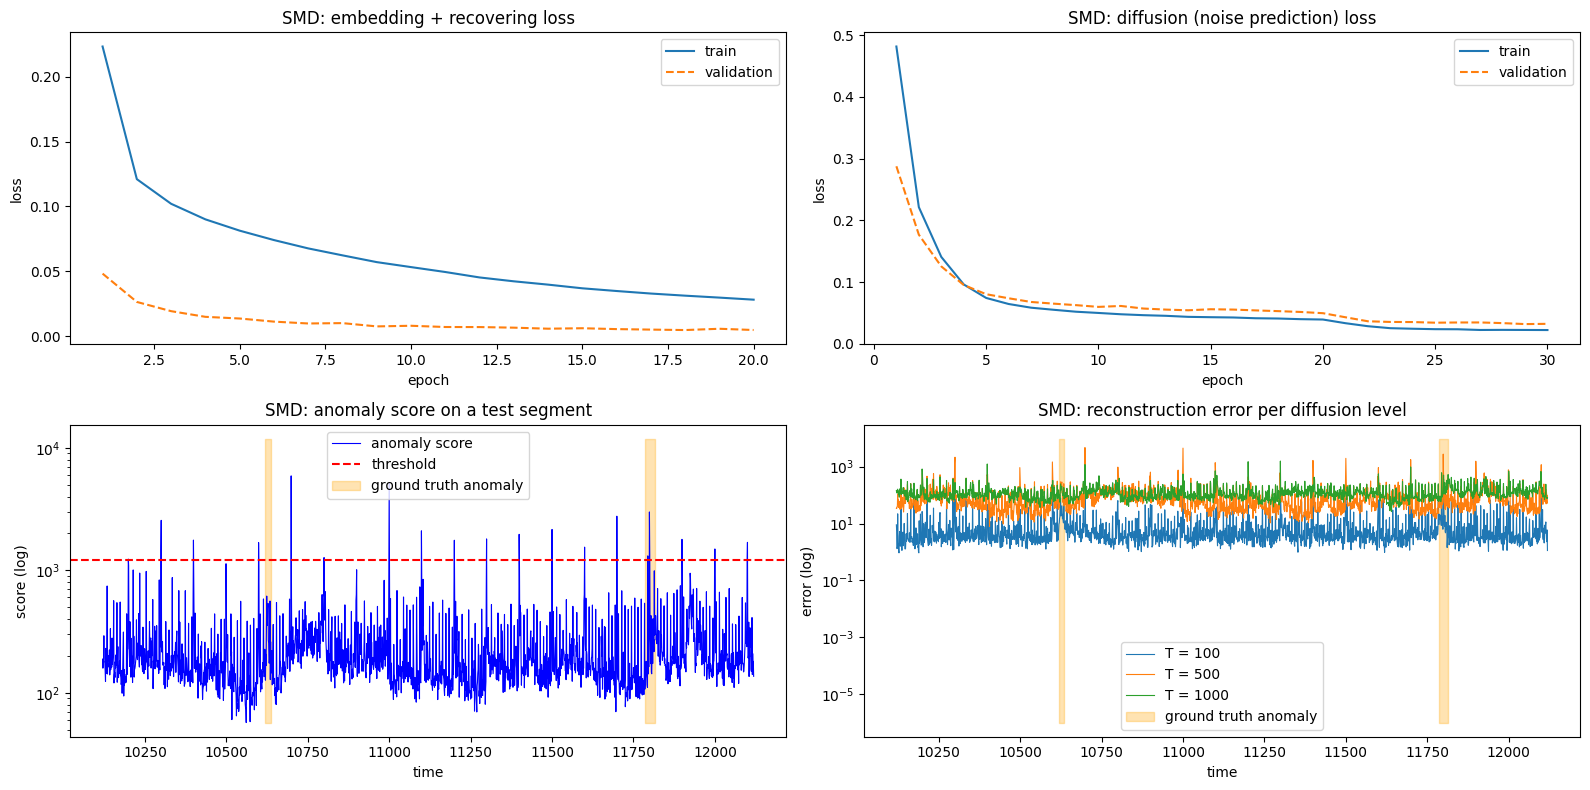

[MSL] dim=55  train=58317  test=73729  anomaly rate in test=10.54%
[MSL] Stage 1: embedding + recovering
  [MSL | embed+recover] epoch   1  train 0.55583  val 0.39966
  [MSL | embed+recover] epoch   2  train 0.39534  val 0.25374
  [MSL | embed+recover] epoch   3  train 0.32402  val 0.20279
  [MSL | embed+recover] epoch   4  train 0.29263  val 0.17305
  [MSL | embed+recover] epoch   5  train 0.26717  val 0.15246
  [MSL | embed+recover] epoch   6  train 0.25604  val 0.13730
  [MSL | embed+recover] epoch   7  train 0.24078  val 0.12481
  [MSL | embed+recover] epoch   8  train 0.23400  val 0.11403
  [MSL | embed+recover] epoch   9  train 0.21893  val 0.10505
  [MSL | embed+recover] epoch  10  train 0.21606  val 0.09718
  [MSL | embed+recover] epoch  11  train 0.20976  val 0.09064
  [MSL | embed+recover] epoch  12  train 0.20660  val 0.08468
  [MSL | embed+recover] epoch  13  train 0.20106  val 0.07920
  [MSL | embed+recover] epoch  14  train 0.19577  val 0.07444
  [MSL | embed+recover] epo

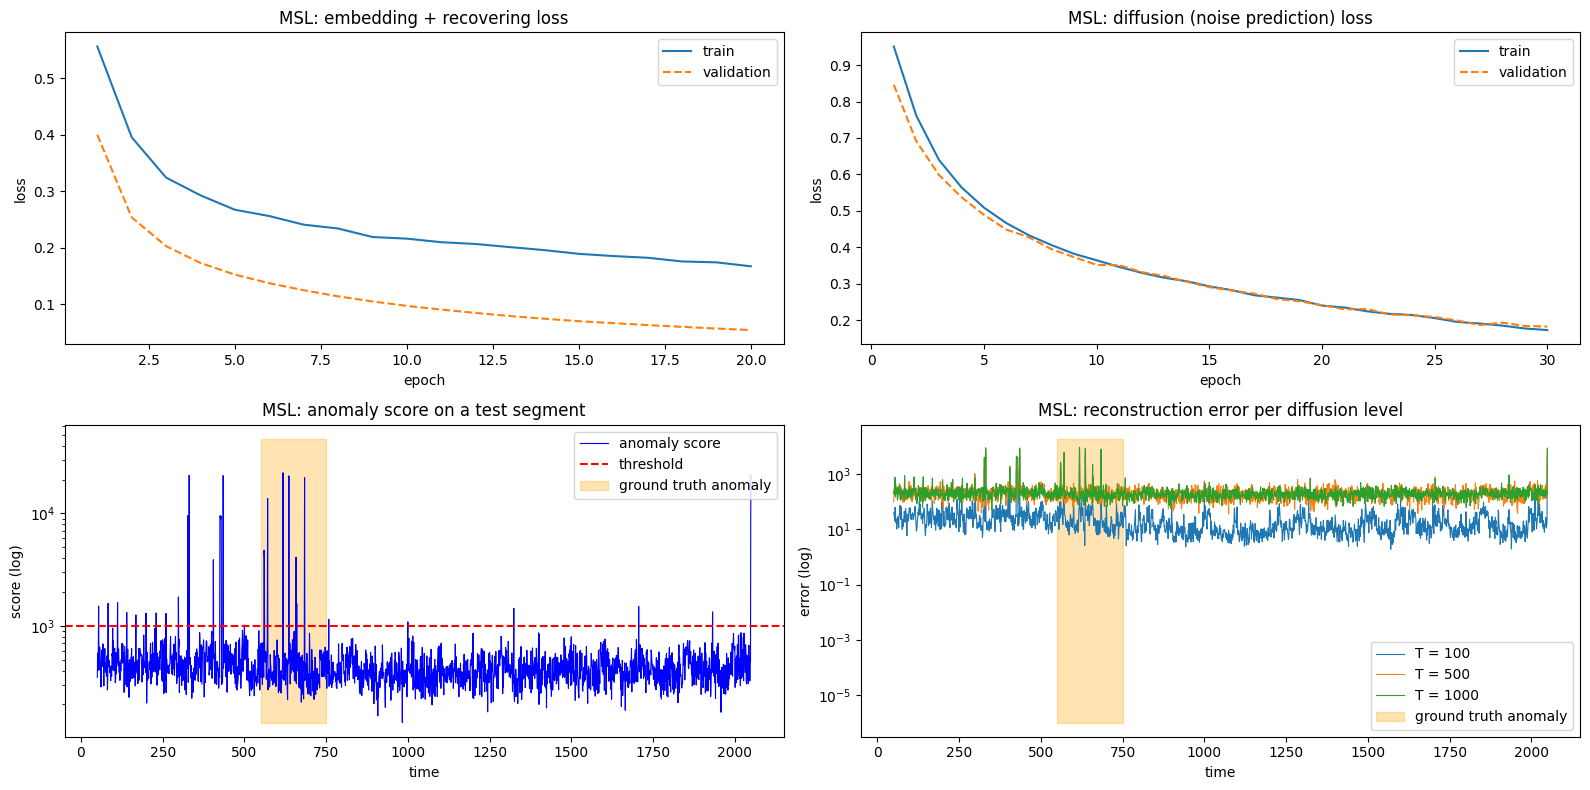

[SMAP] dim=25  train=135183  test=427617  anomaly rate in test=12.79%
[SMAP] Stage 1: embedding + recovering
  [SMAP | embed+recover] epoch   1  train 0.71425  val 0.15207
  [SMAP | embed+recover] epoch   2  train 0.45892  val 0.08901
  [SMAP | embed+recover] epoch   3  train 0.35955  val 0.05800
  [SMAP | embed+recover] epoch   4  train 0.31027  val 0.03931
  [SMAP | embed+recover] epoch   5  train 0.27320  val 0.02708
  [SMAP | embed+recover] epoch   6  train 0.24695  val 0.01912
  [SMAP | embed+recover] epoch   7  train 0.22846  val 0.01388
  [SMAP | embed+recover] epoch   8  train 0.21283  val 0.01060
  [SMAP | embed+recover] epoch   9  train 0.20289  val 0.00836
  [SMAP | embed+recover] epoch  10  train 0.19380  val 0.00691
  [SMAP | embed+recover] epoch  11  train 0.18591  val 0.00632
  [SMAP | embed+recover] epoch  12  train 0.18526  val 0.00547
  [SMAP | embed+recover] epoch  13  train 0.17512  val 0.00496
  [SMAP | embed+recover] epoch  14  train 0.17019  val 0.00458
  [SMAP |

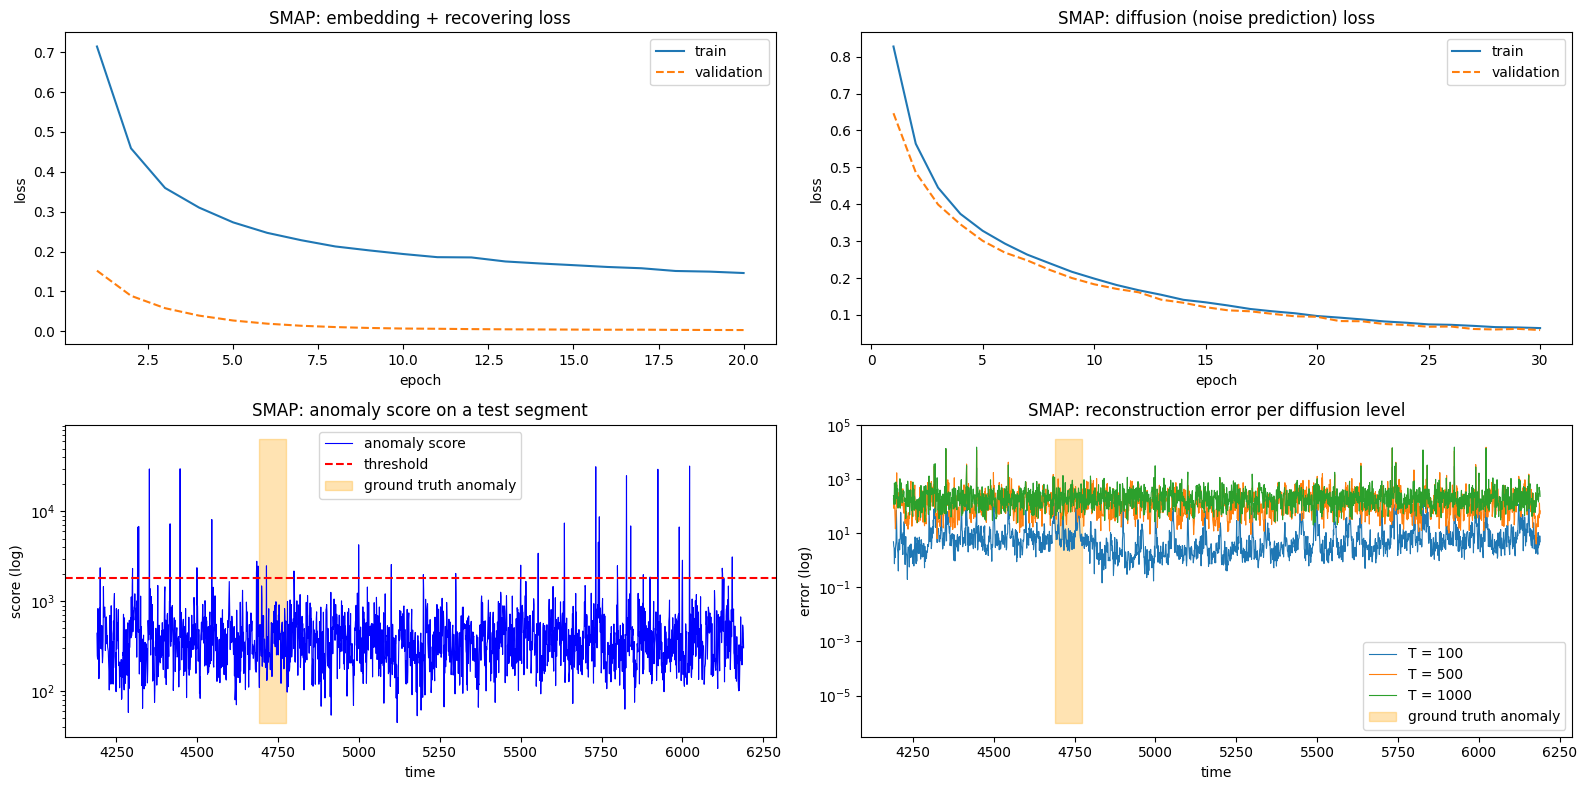

[PSM] dim=25  train=132481  test=87841  anomaly rate in test=27.73%
[PSM] Stage 1: embedding + recovering
  [PSM | embed+recover] epoch   1  train 0.24798  val 0.31132
  [PSM | embed+recover] epoch   2  train 0.06637  val 0.16285
  [PSM | embed+recover] epoch   3  train 0.03629  val 0.11537
  [PSM | embed+recover] epoch   4  train 0.02416  val 0.09352
  [PSM | embed+recover] epoch   5  train 0.01846  val 0.07982
  [PSM | embed+recover] epoch   6  train 0.01503  val 0.06987
  [PSM | embed+recover] epoch   7  train 0.01265  val 0.06177
  [PSM | embed+recover] epoch   8  train 0.01086  val 0.05646
  [PSM | embed+recover] epoch   9  train 0.00941  val 0.05146
  [PSM | embed+recover] epoch  10  train 0.00837  val 0.04866
  [PSM | embed+recover] epoch  11  train 0.00744  val 0.04293
  [PSM | embed+recover] epoch  12  train 0.00671  val 0.04062
  [PSM | embed+recover] epoch  13  train 0.00622  val 0.03835
  [PSM | embed+recover] epoch  14  train 0.00560  val 0.03752
  [PSM | embed+recover] ep

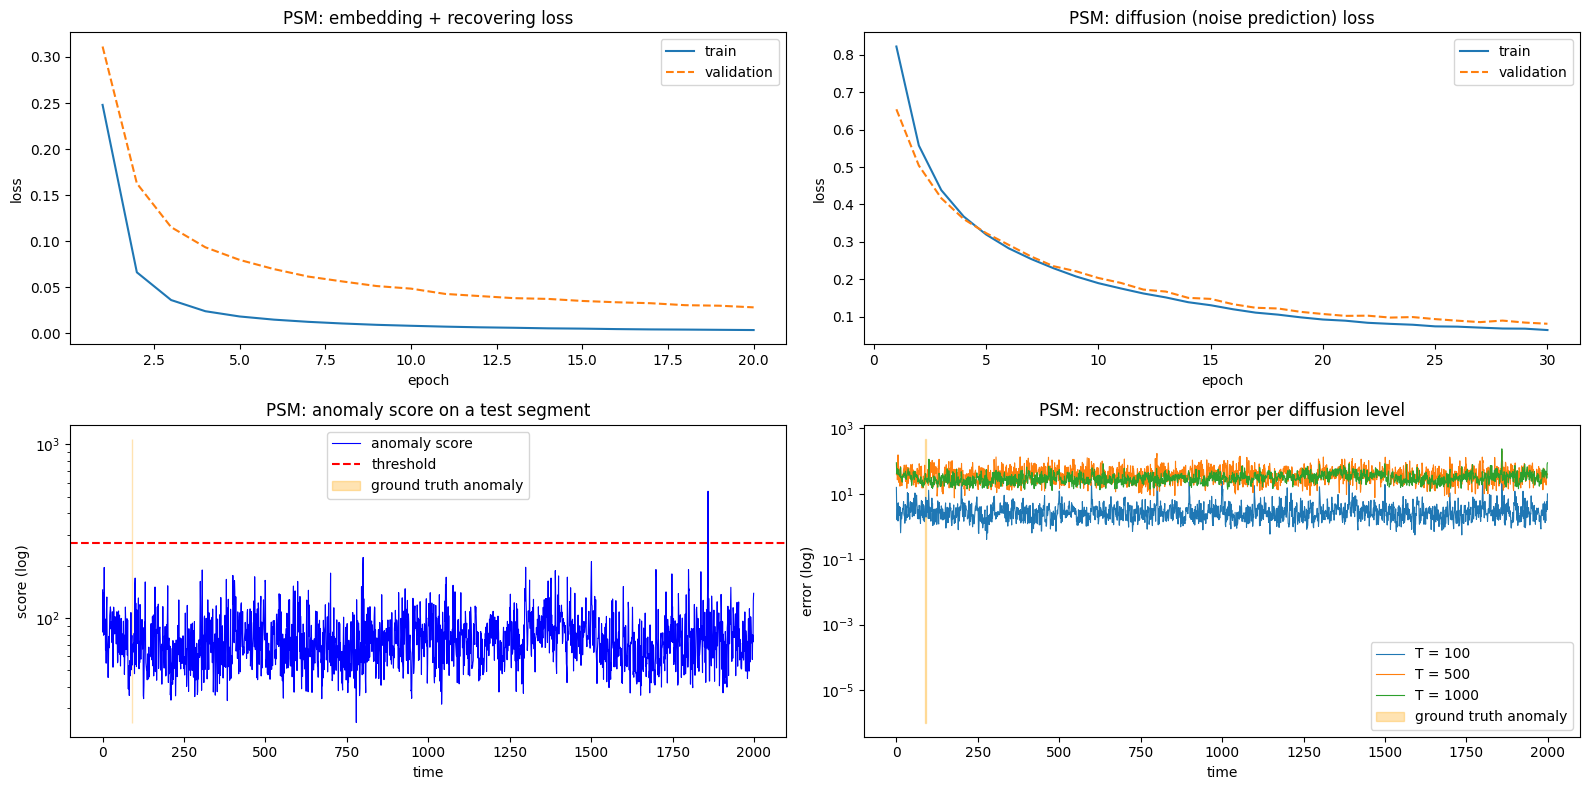

[WADI] files not found under ./dataset -> skipped.

dataset      P      R     F1  best_F1
    SMD 0.7349 0.9348 0.8229   0.8753
    MSL 0.8990 0.8542 0.8761   0.8859
   SMAP 0.9414 0.9767 0.9587   0.9657
    PSM 0.9699 0.9186 0.9436   0.9458


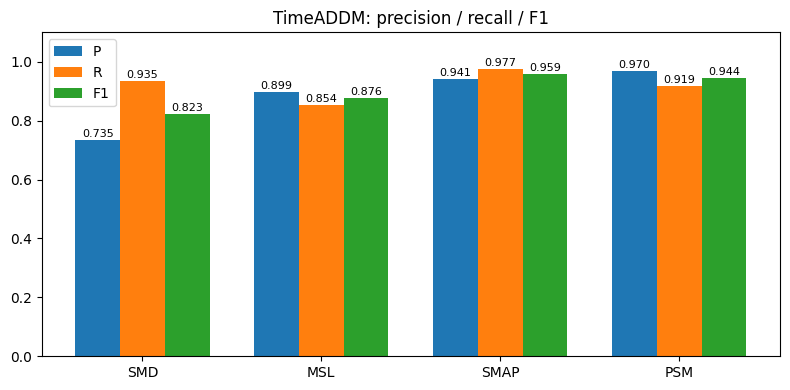

In [5]:
# =============================================================================
# TimeADDM: Unsupervised Anomaly Detection for Multivariate Time Series
# Datasets run here: SMD, MSL, SMAP, PSM (auto-download) and WADI (only if you upload it)
# =============================================================================

import os, glob, math, random, subprocess, sys, zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler

# ----------------------------------------------------------------------------
# 0. Configuration
# ----------------------------------------------------------------------------
class Config:
    data_root  = "./dataset"
    datasets   = ["SMD", "MSL", "SMAP", "PSM", "WADI"]   # WADI is skipped if its files are missing
    gdrive_ids = {"SMD":  "187cjlXCedf4v3-Xm-fK7iTQZ6k6BFaDK",
                  "MSL":  "1BGeu0yiV4T_nsI1G2ayuGfLjIKw9ArZ_",
                  "SMAP": "1DRj6A4wFGx7SNEalGkEPzRi8Td8RdEK1",
                  "PSM":  "1kohMqejb7f787XtpM4b5HR7G22nH-rEF"}

    win_size   = 100        # p: window length (must be divisible by 4 for the U-Net)
    train_step = 10         # stride of training windows (test windows are non-overlapped)
    val_ratio  = 0.2

    hidden     = 64         # latent dimension of the embedding GRU
    unet_ch    = 64         # base channel width of the 1-D U-Net

    T          = 1000       # total diffusion steps
    beta_start = 1e-4
    beta_end   = 0.02
    levels     = [100, 500, 1000]   # diffusion levels T_j used for detection (Fig. 1)
    lambdas    = [1.0, 1.0, 1.0]    # weights lambda_j in Eq. (8)
    ddim_steps = 10         # denoising steps per reconstruction (Eq. 7, sigma = 0)

    ae_epochs   = 20        # stage 1: embedding + recovering
    diff_epochs = 30        # stage 2: diffusion (U-Net) on the latent features
    lr          = 1e-3
    diff_lr     = 2e-4
    batch_size  = 64
    eval_batch  = 256

    anomaly_ratio = 1.0     # threshold = top-p% of the train + validation scores
    point_adjust  = True    # point-adjusted metrics (set False for raw point-wise metrics)
    seed   = 2024
    device = "cuda" if torch.cuda.is_available() else "cpu"

cfg = Config()


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


# ----------------------------------------------------------------------------
# 1. Data
# ----------------------------------------------------------------------------
def download_data():
    os.makedirs(cfg.data_root, exist_ok=True)
    for name, fid in cfg.gdrive_ids.items():
        target = os.path.join(cfg.data_root, name)
        if os.path.isdir(target):
            continue
        zpath = os.path.join(cfg.data_root, f"{name}.zip")
        if not os.path.exists(zpath):
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "gdown"], check=True)
            import gdown
            gdown.download(id=fid, output=zpath, quiet=False)
        print(f"Extracting {name}.zip ...")
        with zipfile.ZipFile(zpath) as f:
            f.extractall(target)


def _find(pattern):
    hits = glob.glob(os.path.join(cfg.data_root, "**", pattern), recursive=True)
    return hits[0] if hits else None


def load_raw(name):
    """Returns train (T,d), test (T',d), labels (T',)  or None if the files are missing."""
    if name == "PSM":
        paths = [_find(os.path.join("PSM", f)) for f in ("train.csv", "test.csv", "test_label.csv")]
        if None in paths:
            return None
        train = np.nan_to_num(pd.read_csv(paths[0]).values[:, 1:].astype(np.float64))
        test  = np.nan_to_num(pd.read_csv(paths[1]).values[:, 1:].astype(np.float64))
        label = pd.read_csv(paths[2]).values[:, 1:]
    else:
        paths = [_find(f"{name}_{s}.npy") for s in ("train", "test", "test_label")]
        if None in paths:
            return None
        train = np.nan_to_num(np.load(paths[0]).astype(np.float64))
        test  = np.nan_to_num(np.load(paths[1]).astype(np.float64))
        label = np.load(paths[2])
    label = np.asarray(label).reshape(-1).astype(int)
    scaler = StandardScaler().fit(train)
    return (scaler.transform(train).astype(np.float32),
            scaler.transform(test).astype(np.float32), label)


class WindowDataset(Dataset):
    def __init__(self, data, win, step):
        self.data, self.win, self.step = data, win, step
        self.n = (len(data) - win) // step + 1

    def __len__(self):
        return self.n

    def __getitem__(self, i):
        s = i * self.step
        return torch.from_numpy(self.data[s:s + self.win])


def make_loaders(name):
    raw = load_raw(name)
    if raw is None:
        return None
    train, test, label = raw
    split = int(len(train) * (1 - cfg.val_ratio))
    p = cfg.win_size
    tr_ds  = WindowDataset(train[:split], p, cfg.train_step)
    va_ds  = WindowDataset(train[split:], p, cfg.train_step)
    ref_ds = WindowDataset(train, p, p)       # non-overlapped train windows for the threshold
    te_ds  = WindowDataset(test, p, p)        # non-overlapped test windows
    label  = label[: len(te_ds) * p]
    kw = dict(num_workers=2, pin_memory=True)
    loaders = {
        "train": DataLoader(tr_ds,  batch_size=cfg.batch_size, shuffle=True, drop_last=True, **kw),
        "val":   DataLoader(va_ds,  batch_size=cfg.eval_batch, shuffle=False, **kw),
        "ref":   DataLoader(ref_ds, batch_size=cfg.eval_batch, shuffle=False, **kw),
        "test":  DataLoader(te_ds,  batch_size=cfg.eval_batch, shuffle=False, **kw),
    }
    print(f"[{name}] dim={train.shape[1]}  train={len(train)}  test={len(test)}  "
          f"anomaly rate in test={label.mean()*100:.2f}%")
    return loaders, label, train.shape[1]


# ----------------------------------------------------------------------------
# 2. Model
# ----------------------------------------------------------------------------
class Embedder(nn.Module):
    """Eq. (1): h_t = E(h_{t-1}, x_t);  z = h_{1:tau}"""
    def __init__(self, d, hidden):
        super().__init__()
        self.rnn = nn.GRU(d, hidden, batch_first=True)

    def forward(self, x):                    # (B, p, d) -> (B, p, H), values in (-1, 1)
        z, _ = self.rnn(x)
        return z


class Recovery(nn.Module):
    """Eq. (2): x_hat_t = R_x(h~_t),  h~_t = R_h(h~_{t-1}, x_hat_{t-1}).
    The initial hidden state is formed from the (reconstructed) latent feature;
    the latent z_t is also fed to R_h at every step so the whole latent sequence is used."""
    def __init__(self, d, hidden):
        super().__init__()
        self.d = d
        self.init = nn.Linear(hidden, hidden)
        self.cell = nn.GRUCell(d + hidden, hidden)     # R_h
        self.out  = nn.Linear(hidden, d)               # R_x

    def forward(self, z):                    # (B, p, H) -> (B, p, d)
        B, p, _ = z.shape
        h = torch.tanh(self.init(z[:, -1]))
        x_prev = z.new_zeros(B, self.d)
        outs = []
        for t in range(p):
            h = self.cell(torch.cat([x_prev, z[:, t]], dim=-1), h)
            x_prev = self.out(h)
            outs.append(x_prev)
        return torch.stack(outs, dim=1)


def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([args.sin(), args.cos()], dim=-1)


class ResBlock(nn.Module):
    def __init__(self, cin, cout, tdim):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, cin), nn.Conv1d(cin, cout, 3, padding=1)
        self.n2, self.c2 = nn.GroupNorm(8, cout), nn.Conv1d(cout, cout, 3, padding=1)
        self.t = nn.Linear(tdim, cout)
        self.skip = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, temb):
        h = self.c1(F.silu(self.n1(x)))
        h = h + self.t(temb)[:, :, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.skip(x)


class UNet1D(nn.Module):
    """1-D U-Net that predicts the noise eps_theta(z_t, t) on the latent sequence."""
    def __init__(self, hidden, c):
        super().__init__()
        self.c = c
        tdim = 4 * c
        self.tmlp = nn.Sequential(nn.Linear(c, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
        self.inp   = nn.Conv1d(hidden, c, 3, padding=1)
        self.d1    = ResBlock(c, c, tdim)
        self.down1 = nn.Conv1d(c, c, 4, 2, 1)
        self.d2    = ResBlock(c, 2 * c, tdim)
        self.down2 = nn.Conv1d(2 * c, 2 * c, 4, 2, 1)
        self.mid   = ResBlock(2 * c, 2 * c, tdim)
        self.up2   = nn.ConvTranspose1d(2 * c, 2 * c, 4, 2, 1)
        self.u2    = ResBlock(4 * c, c, tdim)
        self.up1   = nn.ConvTranspose1d(c, c, 4, 2, 1)
        self.u1    = ResBlock(2 * c, c, tdim)
        self.out   = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), nn.Conv1d(c, hidden, 3, padding=1))

    def forward(self, z, t):                 # z: (B, p, H), t: (B,)
        temb = self.tmlp(timestep_embedding(t, self.c))
        x  = self.inp(z.transpose(1, 2))
        h1 = self.d1(x, temb)
        h2 = self.d2(self.down1(h1), temb)
        m  = self.mid(self.down2(h2), temb)
        u  = self.u2(torch.cat([self.up2(m), h2], dim=1), temb)
        u  = self.u1(torch.cat([self.up1(u), h1], dim=1), temb)
        return self.out(u).transpose(1, 2)


class TimeADDM(nn.Module):
    def __init__(self, d):
        super().__init__()
        assert cfg.win_size % 4 == 0, "win_size must be divisible by 4"
        self.embed = Embedder(d, cfg.hidden)
        self.recover = Recovery(d, cfg.hidden)
        self.unet = UNet1D(cfg.hidden, cfg.unet_ch)
        betas = torch.linspace(cfg.beta_start, cfg.beta_end, cfg.T)
        self.register_buffer("abar", torch.cumprod(1 - betas, dim=0))   # alpha_t in the paper

    # ---- forward diffusion: z_t ~ p_t(z_t | z_0)
    def q_sample(self, z0, t, eps):
        a = self.abar[t].view(-1, 1, 1)
        return a.sqrt() * z0 + (1 - a).sqrt() * eps

    # ---- training objective, Eq. (6)
    def diffusion_loss(self, z0):
        t = torch.randint(0, cfg.T, (z0.size(0),), device=z0.device)
        eps = torch.randn_like(z0)
        return F.mse_loss(self.unet(self.q_sample(z0, t, eps), t), eps)

    # ---- diffuse z to level T_j, then denoise back with the fast sampler of Eq. (7), sigma = 0
    @torch.no_grad()
    def reconstruct_latent(self, z0, level):
        B = z0.size(0)
        seq = np.unique(np.linspace(0, level - 1, min(cfg.ddim_steps, level)).round().astype(int))
        t = torch.full((B,), int(seq[-1]), device=z0.device, dtype=torch.long)
        z = self.q_sample(z0, t, torch.randn_like(z0))
        for i in range(len(seq) - 1, -1, -1):
            t = torch.full((B,), int(seq[i]), device=z0.device, dtype=torch.long)
            a_t = self.abar[seq[i]]
            a_prev = self.abar[seq[i - 1]] if i > 0 else torch.ones_like(a_t)
            eps = self.unet(z, t)
            z0_hat = ((z - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1, 1)
            z = a_prev.sqrt() * z0_hat + (1 - a_prev).sqrt() * eps
        return z


# ----------------------------------------------------------------------------
# 3. Training
# ----------------------------------------------------------------------------
def train_autoencoder(model, loaders, name):
    params = list(model.embed.parameters()) + list(model.recover.parameters())
    opt = torch.optim.Adam(params, lr=cfg.lr)
    hist = {"train": [], "val": []}
    for ep in range(1, cfg.ae_epochs + 1):
        model.train(); tot, n = 0.0, 0
        for x in loaders["train"]:
            x = x.to(cfg.device)
            loss = F.mse_loss(model.recover(model.embed(x)), x)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(params, 1.0); opt.step()
            tot += loss.item() * len(x); n += len(x)
        model.eval(); vt, vn = 0.0, 0
        with torch.no_grad():
            for x in loaders["val"]:
                x = x.to(cfg.device)
                vt += F.mse_loss(model.recover(model.embed(x)), x).item() * len(x); vn += len(x)
        hist["train"].append(tot / n); hist["val"].append(vt / vn)
        print(f"  [{name} | embed+recover] epoch {ep:3d}  train {tot/n:.5f}  val {vt/vn:.5f}")
    return hist


def train_diffusion(model, loaders, name):
    opt = torch.optim.Adam(model.unet.parameters(), lr=cfg.diff_lr)
    hist = {"train": [], "val": []}
    model.embed.eval()
    for ep in range(1, cfg.diff_epochs + 1):
        model.unet.train(); tot, n = 0.0, 0
        for x in loaders["train"]:
            x = x.to(cfg.device)
            with torch.no_grad():
                z = model.embed(x)
            loss = model.diffusion_loss(z)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.unet.parameters(), 1.0); opt.step()
            tot += loss.item() * len(x); n += len(x)
        model.unet.eval(); vt, vn = 0.0, 0
        with torch.no_grad():
            for x in loaders["val"]:
                x = x.to(cfg.device)
                vt += model.diffusion_loss(model.embed(x)).item() * len(x); vn += len(x)
        hist["train"].append(tot / n); hist["val"].append(vt / vn)
        print(f"  [{name} | diffusion] epoch {ep:3d}  train {tot/n:.5f}  val {vt/vn:.5f}")
    return hist


# ----------------------------------------------------------------------------
# 4. Anomaly scoring and evaluation
# ----------------------------------------------------------------------------
@torch.no_grad()
def anomaly_scores(model, loader):
    """Eq. (8): A_k = sum_j lambda_j * || s_k - s_hat_k^(T_j) ||^2"""
    model.eval()
    total, per_level = [], [[] for _ in cfg.levels]
    for x in loader:
        x = x.to(cfg.device)
        z = model.embed(x)
        score = torch.zeros(x.shape[:2], device=x.device)
        for j, (lvl, lam) in enumerate(zip(cfg.levels, cfg.lambdas)):
            x_hat = model.recover(model.reconstruct_latent(z, lvl))
            err = ((x - x_hat) ** 2).sum(-1)              # (B, p)
            per_level[j].append(err.reshape(-1).cpu().numpy())
            score += lam * err
        total.append(score.reshape(-1).cpu().numpy())
    return np.concatenate(total), [np.concatenate(e) for e in per_level]


def point_adjust(pred, gt):
    pred = pred.copy()
    d = np.diff(np.concatenate([[0], gt, [0]]))
    for s, e in zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)):
        if pred[s:e].any():
            pred[s:e] = 1
    return pred


def prf(scores, label, thresh):
    pred = (scores > thresh).astype(int)
    if cfg.point_adjust:
        pred = point_adjust(pred, label)
    tp = int(((pred == 1) & (label == 1)).sum())
    fp = int(((pred == 1) & (label == 0)).sum())
    fn = int(((pred == 0) & (label == 1)).sum())
    p = tp / (tp + fp + 1e-12); r = tp / (tp + fn + 1e-12)
    return p, r, 2 * p * r / (p + r + 1e-12)


# ----------------------------------------------------------------------------
# 5. Plots
# ----------------------------------------------------------------------------
def plot_dataset(name, h_ae, h_df, scores, levels_err, label, thresh, seg_len=2000):
    fig, ax = plt.subplots(2, 2, figsize=(16, 8))

    for a, h, title in ((ax[0, 0], h_ae, "embedding + recovering loss"),
                        (ax[0, 1], h_df, "diffusion (noise prediction) loss")):
        e = np.arange(1, len(h["train"]) + 1)
        a.plot(e, h["train"], label="train"); a.plot(e, h["val"], "--", label="validation")
        a.set_xlabel("epoch"); a.set_ylabel("loss"); a.set_title(f"{name}: {title}"); a.legend()

    anom = np.flatnonzero(label == 1)
    start = max(0, (anom[0] if len(anom) else 0) - seg_len // 4)
    end = min(len(scores), start + seg_len)
    t = np.arange(start, end); gt = label[start:end] == 1

    s = scores[start:end] + 1e-12
    ax[1, 0].plot(t, s, "b-", lw=0.8, label="anomaly score")
    ax[1, 0].axhline(thresh, color="r", ls="--", label="threshold")
    ax[1, 0].fill_between(t, s.min(), max(s.max(), thresh) * 2, where=gt,
                          color="orange", alpha=0.3, label="ground truth anomaly")
    ax[1, 0].set_yscale("log"); ax[1, 0].set_xlabel("time"); ax[1, 0].set_ylabel("score (log)")
    ax[1, 0].set_title(f"{name}: anomaly score on a test segment"); ax[1, 0].legend()

    top = 0
    for lvl, err in zip(cfg.levels, levels_err):
        e = err[start:end] + 1e-12
        ax[1, 1].plot(t, e, lw=0.8, label=f"T = {lvl}"); top = max(top, e.max())
    ax[1, 1].fill_between(t, 1e-6, top * 2, where=gt, color="orange", alpha=0.3,
                          label="ground truth anomaly")
    ax[1, 1].set_yscale("log"); ax[1, 1].set_xlabel("time"); ax[1, 1].set_ylabel("error (log)")
    ax[1, 1].set_title(f"{name}: reconstruction error per diffusion level"); ax[1, 1].legend()

    plt.tight_layout(); plt.savefig(f"timeaddm_{name}_plots.png", dpi=120); plt.show()


def plot_summary(results):
    names = [r["dataset"] for r in results]
    x, w = np.arange(len(names)), 0.25
    plt.figure(figsize=(8, 4))
    for k, key in enumerate(["P", "R", "F1"]):
        vals = [r[key] for r in results]
        bars = plt.bar(x + (k - 1) * w, vals, w, label=key)
        for b, v in zip(bars, vals):
            plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
    plt.xticks(x, names); plt.ylim(0, 1.1); plt.legend()
    plt.title("TimeADDM: precision / recall / F1")
    plt.tight_layout(); plt.savefig("timeaddm_summary.png", dpi=120); plt.show()


# ----------------------------------------------------------------------------
# 6. Full pipeline for one dataset
# ----------------------------------------------------------------------------
def run(name):
    set_seed(cfg.seed)
    made = make_loaders(name)
    if made is None:
        print(f"[{name}] files not found under {cfg.data_root} -> skipped.\n")
        return None
    loaders, label, d = made
    model = TimeADDM(d).to(cfg.device)

    print(f"[{name}] Stage 1: embedding + recovering")
    h_ae = train_autoencoder(model, loaders, name)
    print(f"[{name}] Stage 2: diffusion on the latent features")
    h_df = train_diffusion(model, loaders, name)

    print(f"[{name}] Scoring ...")
    ref_s, _ = anomaly_scores(model, loaders["ref"])
    test_s, levels_err = anomaly_scores(model, loaders["test"])
    thresh = np.percentile(ref_s, 100 - cfg.anomaly_ratio)
    p, r, f1 = prf(test_s, label, thresh)

    # For reference only: best F1 over thresholds (uses the test labels)
    best = max((prf(test_s, label, th) for th in np.quantile(test_s, np.linspace(0.5, 0.999, 100))),
               key=lambda m: m[2])

    print(f"[{name}] threshold={thresh:.5g}  P={p:.4f}  R={r:.4f}  F1={f1:.4f}   "
          f"(best-F1 threshold search: P={best[0]:.4f} R={best[1]:.4f} F1={best[2]:.4f})\n")
    torch.save(model.state_dict(), f"timeaddm_{name}.pt")
    plot_dataset(name, h_ae, h_df, test_s, levels_err, label, thresh)
    return {"dataset": name, "P": p, "R": r, "F1": f1, "best_F1": best[2]}


if __name__ == "__main__":
    print("Device:", cfg.device)
    download_data()
    results = [r for r in (run(n) for n in cfg.datasets) if r is not None]
    print("=" * 60)
    print(pd.DataFrame(results).round(4).to_string(index=False))
    plot_summary(results)
